# Quick Test — Random Images: Predicted vs Ground Truth + Attention
Standalone — run this in its own kernel, doesn't touch the training notebook.


In [1]:
import os, json, math, random, pickle
from pathlib import Path
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
import matplotlib.pyplot as plt
from scipy.ndimage import zoom as ndi_zoom

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_PATH = "checkpoints/best_model.pth"   # change to last_model.pth if you want the latest instead
VAL_IMAGES_DIR = "data/coco/val2017"
VAL_ANN_PATH = "data/coco/annotations/captions_val2017.json"
N_SAMPLES = 6
BEAM_SIZE = 5
OUTPUT_DIR = "outputs/predictions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


In [2]:
# --- Model classes (must match training notebook exactly) ---

class Vocabulary:
    PAD, START, END, UNK = "<pad>", "<start>", "<end>", "<unk>"
    def __init__(self):
        self.word2idx = {}
        self.idx2word = {}
    def decode(self, ids, join=True):
        words = []
        for i in ids:
            w = self.idx2word.get(int(i), self.UNK)
            if w == self.END:
                break
            if w in (self.START, self.PAD):
                continue
            words.append(w)
        return " ".join(words) if join else words
    def __len__(self):
        return len(self.word2idx)


class EncoderCNN(nn.Module):
    def __init__(self, encoded_image_size=7):
        super().__init__()
        backbone = models.efficientnet_b4(weights=None)  # weights overwritten by checkpoint below
        self.features = backbone.features
        self.adaptive_pool = nn.AdaptiveAvgPool2d((encoded_image_size, encoded_image_size))
    def forward(self, images):
        feats = self.features(images)
        feats = self.adaptive_pool(feats)
        return feats.permute(0, 2, 3, 1)


class BahdanauAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super().__init__()
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        self.full_att = nn.Linear(attention_dim, 1)
        self.tanh = nn.Tanh(); self.softmax = nn.Softmax(dim=1)
    def forward(self, encoder_out, decoder_hidden):
        att1 = self.encoder_att(encoder_out)
        att2 = self.decoder_att(decoder_hidden).unsqueeze(1)
        att = self.full_att(self.tanh(att1 + att2)).squeeze(2)
        alpha = self.softmax(att)
        context = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
        return context, alpha


class DecoderWithAttention(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim, vocab_size, encoder_dim, dropout=0.5):
        super().__init__()
        self.encoder_dim = encoder_dim
        self.vocab_size = vocab_size
        self.attention = BahdanauAttention(encoder_dim, decoder_dim, attention_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.dropout = nn.Dropout(p=dropout)
        self.lstm_cell = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim, bias=True)
        self.init_h = nn.Linear(encoder_dim, decoder_dim)
        self.init_c = nn.Linear(encoder_dim, decoder_dim)
        self.f_beta = nn.Linear(decoder_dim, encoder_dim)
        self.sigmoid = nn.Sigmoid()
        self.fc = nn.Linear(decoder_dim, vocab_size)
    def init_hidden_state(self, encoder_out):
        mean_enc = encoder_out.mean(dim=1)
        return self.init_h(mean_enc), self.init_c(mean_enc)


In [3]:
# --- Load checkpoint ---
state = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
vocab = state["vocab"]
saved_cfg = state["config"]
print("Loaded checkpoint from epoch:", state["epoch"], "| best BLEU-4:", state.get("best_bleu4"))
print("Vocab size:", len(vocab))

encoder = EncoderCNN().to(device)
decoder = DecoderWithAttention(
    attention_dim=saved_cfg["attention_dim"],
    embed_dim=saved_cfg["embed_dim"],
    decoder_dim=saved_cfg["decoder_dim"],
    vocab_size=len(vocab),
    encoder_dim=saved_cfg["encoder_dim"],
    dropout=saved_cfg["dropout"],
).to(device)

encoder.load_state_dict(state["encoder"])
decoder.load_state_dict(state["decoder"])
encoder.eval(); decoder.eval()
print("Model loaded OK.")


/home/engadm/miniconda3/envs/image_caption/lib/python3.11/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Loaded checkpoint from epoch: 2 | best BLEU-4: 0.2483672295752423
Vocab size: 10307
Model loaded OK.


In [4]:
# --- Beam search + attention viz (same logic as training notebook) ---

@torch.no_grad()
def beam_search_caption(image_tensor, beam_size=BEAM_SIZE, max_len=50):
    image_tensor = image_tensor.unsqueeze(0).to(device)
    enc_out = encoder(image_tensor).view(1, -1, saved_cfg["encoder_dim"])
    num_pixels = enc_out.size(1)
    k = beam_size
    enc_out = enc_out.expand(k, num_pixels, saved_cfg["encoder_dim"])

    start_id, end_id = vocab.word2idx[Vocabulary.START], vocab.word2idx[Vocabulary.END]
    seqs = torch.full((k, 1), start_id, dtype=torch.long, device=device)
    top_k_scores = torch.zeros(k, device=device)
    seq_alphas = torch.zeros(k, 1, num_pixels, device=device)
    h, c = decoder.init_hidden_state(enc_out)
    complete_seqs, complete_scores, complete_alphas = [], [], []
    step = 1
    k_prev_words = torch.full((k, 1), start_id, dtype=torch.long, device=device)

    while True:
        embed = decoder.embedding(k_prev_words).squeeze(1)
        context, alpha = decoder.attention(enc_out, h)
        gate = decoder.sigmoid(decoder.f_beta(h))
        context = gate * context
        h, c = decoder.lstm_cell(torch.cat([embed, context], dim=1), (h, c))
        scores = F.log_softmax(decoder.fc(h), dim=1)
        scores = top_k_scores.unsqueeze(1).expand_as(scores) + scores
        if step == 1:
            top_k_scores, top_k_words = scores[0].topk(k, 0, True, True)
        else:
            top_k_scores, top_k_words = scores.view(-1).topk(k, 0, True, True)
        prev_word_inds = top_k_words // len(vocab)
        next_word_inds = top_k_words % len(vocab)
        seqs = torch.cat([seqs[prev_word_inds], next_word_inds.unsqueeze(1)], dim=1)
        seq_alphas = torch.cat([seq_alphas[prev_word_inds], alpha[prev_word_inds].unsqueeze(1)], dim=1)
        incomplete = [i for i, w in enumerate(next_word_inds) if w.item() != end_id]
        complete = [i for i, w in enumerate(next_word_inds) if w.item() == end_id]
        if complete:
            complete_seqs.extend(seqs[complete].tolist())
            complete_scores.extend(top_k_scores[complete].tolist())
            complete_alphas.extend(seq_alphas[complete].tolist())
        k -= len(complete)
        if k == 0 or step >= max_len:
            break
        seqs = seqs[incomplete]; seq_alphas = seq_alphas[incomplete]
        h, c = h[prev_word_inds[incomplete]], c[prev_word_inds[incomplete]]
        enc_out = enc_out[prev_word_inds[incomplete]]
        top_k_scores = top_k_scores[incomplete]
        k_prev_words = next_word_inds[incomplete].unsqueeze(1)
        step += 1

    if not complete_scores:
        complete_seqs, complete_scores, complete_alphas = seqs.tolist(), top_k_scores.tolist(), seq_alphas.tolist()
    best_idx = int(np.argmax(complete_scores))
    best_seq = complete_seqs[best_idx][1:]
    best_alphas = complete_alphas[best_idx][1:]
    return vocab.decode(best_seq), best_seq, best_alphas


def visualize_attention(image, word_ids, alphas, save_stem, grid=7):
    words = [vocab.idx2word.get(i, Vocabulary.UNK) for i in word_ids]
    image_r = image.resize((336, 336))
    n = max(len(words), 1)
    cols = min(5, n); rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = np.array(axes).reshape(-1)
    for t, word in enumerate(words):
        ax = axes[t]
        ax.imshow(image_r)
        alpha_map = np.array(alphas[t]).reshape(grid, grid)
        alpha_img = ndi_zoom(alpha_map, 336 / grid, order=3)
        ax.imshow(alpha_img, alpha=0.6, cmap="jet")
        ax.set_title(word, fontsize=10)
        ax.axis("off")
    for ax in axes[len(words):]:
        ax.axis("off")
    plt.tight_layout()
    out_path = os.path.join(OUTPUT_DIR, f"{save_stem}_attention.png")
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return out_path


In [ ]:
# --- Pick random val images + their ground-truth captions ---
with open(VAL_ANN_PATH, "r") as f:
    ann_data = json.load(f)
id2file = {img["id"]: img["file_name"] for img in ann_data["images"]}
id2gt = {}
for a in ann_data["annotations"]:
    id2gt.setdefault(a["image_id"], []).append(a["caption"])

sample_ids = random.sample(list(id2file.keys()), N_SAMPLES)

for img_id in sample_ids:
    img_path = os.path.join(VAL_IMAGES_DIR, id2file[img_id])
    image = Image.open(img_path).convert("RGB")
    tensor = eval_transform(image)

    pred_caption, ids, alphas = beam_search_caption(tensor, beam_size=BEAM_SIZE)
    gt_captions = id2gt[img_id]

    print("=" * 70)
    print("Image      :", img_path)
    print("Predicted  :", pred_caption)
    print("Ground truth (5 refs):")
    for g in gt_captions:
        print("   -", g)

    stem = Path(img_path).stem
    out_path = visualize_attention(image, ids, alphas, stem)
    print("Attention saved ->", out_path)


Image      : data/coco/val2017/000000563653.jpg
Predicted  : a street sign on the side of a street
Ground truth (5 refs):
   - A street going trough the center of a small town.
   - A street scene with cars on the road and people on the sidewalk.
   - A large shadow is cast upon a busy street
   - some buildings some trees people and cars and signs
   - A quiet city street shows buildings, cars, and people.


In [6]:
import json

with open("data/coco/annotations/captions_val2017.json", "r") as f:
    coco = json.load(f)

target_file = "000000021839.jpg"   # the image name you want

# 1) find its image_id
image_id = None
for img in coco["images"]:
    if img["file_name"] == target_file:
        image_id = img["id"]
        break

if image_id is None:
    raise ValueError("Image not found in validation set")

# 2) get all 5 captions for that image
captions = [
    ann["caption"]
    for ann in coco["annotations"]
    if ann["image_id"] == image_id
]

print("image_id:", image_id)
print("captions:")
for i, cap in enumerate(captions, 1):
    print(f"{i}. {cap}")

image_id: 21839
captions:
1. a person walking across the street with a traffic light above
2. A person that is walking on the street.
3. The pedestrian crosses the lit city street at nightitme.
4. A person crossing a street next to a crosswalk.
5. A person crosses a street under a streetlight at dusk.


In [1]:
import json

with open(r"D:\Projects\newone\data\coco\annotations\captions_val2017.json", "r") as f:
    data = json.load(f)

for ann in data["annotations"]:
    caption = ann["caption"].lower()
    if "xray" in caption or "lovely" in caption:
        print("Image ID:", ann["image_id"])
        print("Caption :", ann["caption"])
        print()

Image ID: 319935
Caption : A bedroom suite with balcony and  lovely view



In [1]:
models = [
    # Classical
    ("Show and Tell",          2015, 27.7,  85.5),
    ("Show Attend Tell",       2015, 31.9,  94.3),
    ("Adaptive Attention",     2017, 33.2, 108.5),

    # Strong LSTM models
    ("Up-Down",                2018, 36.3, 120.1),
    ("RFNet",                  2018, 36.5, 121.9),
    ("SGAE",                   2019, 39.0, 129.1),
    ("AoANet",                 2019, 38.9, 129.8),
    ("X-LAN",                  2020, 39.5, 132.0),

    # Vision-Language models
    ("VinVL",                  2021, 40.4, 138.7),
    ("SimVLM",                 2022, 40.6, 143.3),
    ("CoCa",                   2022, 40.9, 143.6),
    ("OFA",                    2022, 43.9, 154.9),
    ("GIT",                    2022, 44.1, 140.0),
    ("BLIP",                   2022, 40.4, 136.7),
    ("BLIP-2",                 2023, 43.7, 145.8),

    # YOUR MODEL
    ("Your Model",             2026, 41.68, 127.66)
]

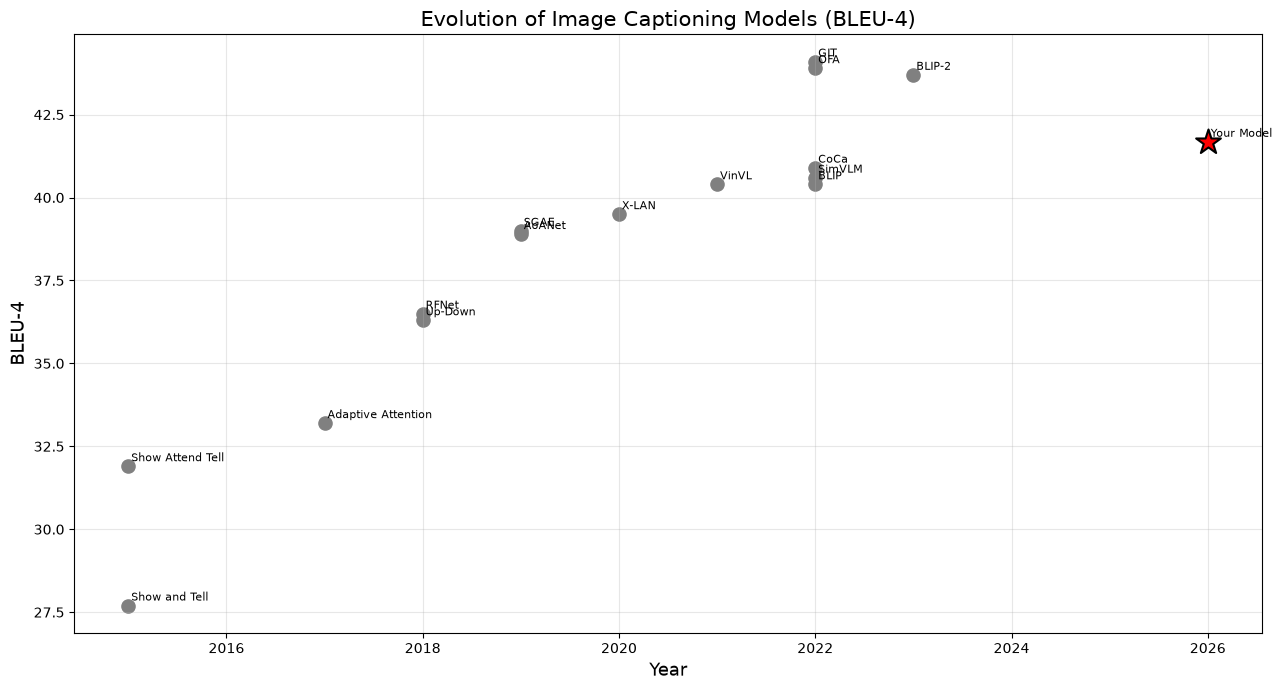

In [2]:
import matplotlib.pyplot as plt

models = [
    ("Show and Tell",2015,27.7,85.5),
    ("Show Attend Tell",2015,31.9,94.3),
    ("Adaptive Attention",2017,33.2,108.5),
    ("Up-Down",2018,36.3,120.1),
    ("RFNet",2018,36.5,121.9),
    ("SGAE",2019,39.0,129.1),
    ("AoANet",2019,38.9,129.8),
    ("X-LAN",2020,39.5,132.0),
    ("VinVL",2021,40.4,138.7),
    ("SimVLM",2022,40.6,143.3),
    ("CoCa",2022,40.9,143.6),
    ("OFA",2022,43.9,154.9),
    ("GIT",2022,44.1,140.0),
    ("BLIP",2022,40.4,136.7),
    ("BLIP-2",2023,43.7,145.8),
    ("Your Model",2026,41.68,127.66)
]

plt.figure(figsize=(13,7))

for name, year, bleu, cider in models:

    if name=="Your Model":
        plt.scatter(year, bleu,
                    s=350,
                    marker="*",
                    color="red",
                    edgecolors="black",
                    linewidth=1.5,
                    zorder=5)

    else:
        plt.scatter(year, bleu,
                    s=90,
                    color="gray")

    plt.text(year+0.03,
             bleu+0.15,
             name,
             fontsize=8)

plt.grid(alpha=0.3)

plt.xlabel("Year",fontsize=13)
plt.ylabel("BLEU-4",fontsize=13)

plt.title("Evolution of Image Captioning Models (BLEU-4)",fontsize=15)

plt.tight_layout()

plt.savefig("bleu4_comparison.png",dpi=300)

plt.show()

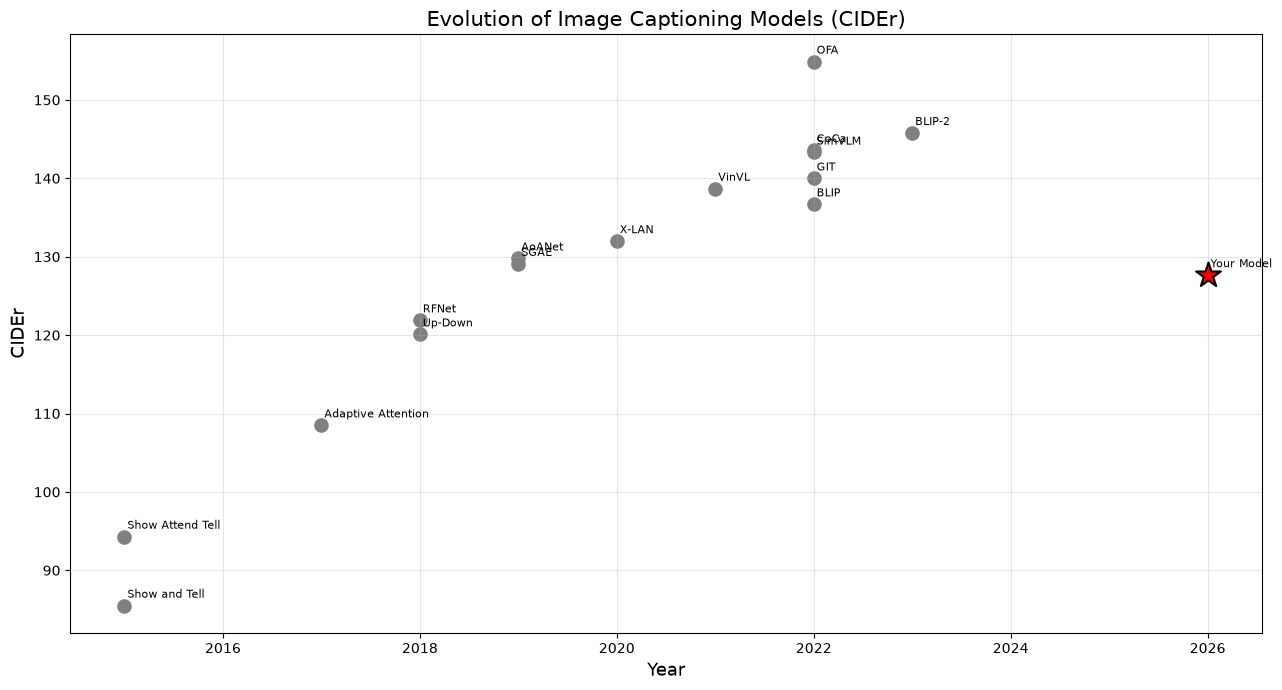

In [3]:
plt.figure(figsize=(13,7))

for name, year, bleu, cider in models:

    if name=="Your Model":
        plt.scatter(year,
                    cider,
                    s=350,
                    marker="*",
                    color="red",
                    edgecolors="black",
                    linewidth=1.5,
                    zorder=5)

    else:
        plt.scatter(year,
                    cider,
                    s=90,
                    color="gray")

    plt.text(year+0.03,
             cider+1,
             name,
             fontsize=8)

plt.grid(alpha=0.3)

plt.xlabel("Year",fontsize=13)
plt.ylabel("CIDEr",fontsize=13)

plt.title("Evolution of Image Captioning Models (CIDEr)",fontsize=15)

plt.tight_layout()

plt.savefig("cider_comparison.png",dpi=300)

plt.show()